# Level 2 — Task 1: Table Booking and Online Delivery

**Cognifyz Technologies — Data Science Internship**

## Introduction
Restaurants differ in the services they offer. Two of the most visible services are **table booking** and **online delivery**. This notebook measures how common each service is, checks whether restaurants that accept table bookings are rated differently, and studies how online delivery availability changes across **price ranges**.

## Objectives
1. Calculate the number and percentage of restaurants that offer table booking.
2. Calculate the number and percentage of restaurants that offer online delivery.
3. Compare the average, median and standard deviation of `Aggregate rating` for restaurants with and without table booking.
4. Analyse online delivery availability within each `Price range` (counts and within-price-range percentages).
5. Present the results in labelled tables and professional charts, with findings generated directly from the data.

## 1. Imports and Notebook Setup
All libraries used here are standard (`pandas`, `numpy`, `matplotlib`, `seaborn`). The helper functions `show_table` and `show_findings` keep the output tidy.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)

# Consistent styling for every chart in this notebook
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({
    "figure.figsize": (10, 5.5),
    "figure.dpi": 100,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "legend.frameon": True,
})
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.2f}".format)


def show_table(table, title):
    """Display a DataFrame with a bold title above it."""
    display(Markdown(f"**{title}**"))
    display(table)


def show_findings(findings):
    """Render a list of strings as a Markdown bullet list."""
    display(Markdown("\n".join(f"- {item}" for item in findings)))

## 2. Load the Dataset
The dataset is read from the relative path `../dataset/Dataset.csv` (this notebook is expected to run from the `Level2` folder). The cell stops with a clear message if the file or a required column is missing.

In [ ]:
DATA_PATH = Path("../dataset/Dataset.csv")   # notebook is run from the Level2 folder
REQUIRED_COLUMNS = ["Has Table booking", "Has Online delivery", "Price range", "Aggregate rating"]

if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Dataset not found at '{DATA_PATH}' (looked in: {DATA_PATH.resolve()}). "
        "Run this notebook from the 'Level2' folder and make sure 'Dataset/Dataset.csv' exists."
    )

try:
    df = pd.read_csv(DATA_PATH, encoding="utf-8-sig")
except UnicodeDecodeError:
    df = pd.read_csv(DATA_PATH, encoding="latin-1")

df.columns = df.columns.str.strip()

missing_columns = [col for col in REQUIRED_COLUMNS if col not in df.columns]
if missing_columns:
    raise KeyError(f"Required column(s) missing from the dataset: {missing_columns}")

print(f"Loaded '{DATA_PATH}' successfully: {df.shape[0]:,} rows x {df.shape[1]} columns")
display(df.head())

Loaded '..\Dataset\Dataset.csv' successfully: 9,551 rows x 21 columns


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,Average Cost for two,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.03,14.57,"French, Japanese, Desserts",1100,Botswana Pula(P),Yes,No,No,No,3,4.80,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.01,14.55,Japanese,1200,Botswana Pula(P),Yes,No,No,No,3,4.50,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.06,14.58,"Seafood, Asian, Filipino, Indian",4000,Botswana Pula(P),Yes,No,No,No,4,4.40,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.06,14.59,"Japanese, Sushi",1500,Botswana Pula(P),No,No,No,No,4,4.90,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.06,14.58,"Japanese, Korean",1500,Botswana Pula(P),Yes,No,No,No,4,4.80,Dark Green,Excellent,229


## 3. Dataset Overview
Before analysing anything we check the shape of the data, the data types of the columns used in this task, their missing values and their distinct values.

In [ ]:
print(f"Dataset shape: {df.shape[0]:,} rows x {df.shape[1]} columns\n")

relevant_columns = ["Has Table booking", "Has Online delivery", "Price range", "Aggregate rating"]

overview = pd.DataFrame({
    "Data Type": df[relevant_columns].dtypes.astype(str),
    "Missing Values": df[relevant_columns].isna().sum(),
    "Missing (%)": df[relevant_columns].isna().mean() * 100,
    "Distinct Values": df[relevant_columns].nunique(dropna=True),
})
overview.index.name = "Column"
show_table(overview, "Relevant columns: data types, missing values and distinct values")

print("Distinct values of the categorical columns:")
for column in ["Has Table booking", "Has Online delivery", "Price range"]:
    print(f"  {column}: {sorted(df[column].dropna().unique().tolist())}")
print(f"  Aggregate rating: min = {df['Aggregate rating'].min()}, max = {df['Aggregate rating'].max()}")

Dataset shape: 9,551 rows x 21 columns



**Relevant columns: data types, missing values and distinct values**

,Data Type,Missing Values,Missing (%),Distinct Values
Column,,,,
Has Table booking,str,0,0.00,2
Has Online delivery,str,0,0.00,2
Price range,int64,0,0.00,4
Aggregate rating,float64,0,0.00,33


Distinct values of the categorical columns:
  Has Table booking: ['No', 'Yes']
  Has Online delivery: ['No', 'Yes']
  Price range: [1, 2, 3, 4]
  Aggregate rating: min = 0.0, max = 4.9


## 4. Data Preparation
Care is needed with three columns:

* **Yes/No columns** – values are stripped and case-normalised. Anything that is missing or not recognisably "Yes" or "No" stays **missing**; it is never silently counted as "No".
* **Price range** – converted to a number. Rows with a missing price range are excluded only from the price-range analysis (and the number excluded is reported).
* **Aggregate rating** – in this dataset a rating of `0` is normally used for restaurants that have **not been rated yet** (their `Rating text` is "Not rated"). Including these zeros would pull averages down artificially, so rating statistics are calculated on **rated restaurants only** (rating > 0). The number of unrated restaurants is reported so nothing is hidden.

In [ ]:
def normalize_yes_no(series):
    """Return a Series containing only 'Yes', 'No' or NaN.

    Whitespace and capitalisation are ignored ('yes ', 'YES' -> 'Yes').
    Missing or unrecognised values stay NaN - they are NOT treated as 'No'.
    """
    cleaned = series.astype("string").str.strip().str.lower()
    is_yes = cleaned.eq("yes").fillna(False).to_numpy(dtype=bool)
    is_no = cleaned.eq("no").fillna(False).to_numpy(dtype=bool)
    result = pd.Series(np.nan, index=series.index, dtype=object)
    result[is_yes] = "Yes"
    result[is_no] = "No"
    return result


def report_unexpected(series, column_name):
    """Print how many values are missing or not recognised as Yes/No."""
    cleaned = series.astype("string").str.strip().str.lower()
    n_missing = int(series.isna().sum())
    n_unexpected = int((cleaned.notna() & ~cleaned.isin(["yes", "no"])).sum())
    print(f"{column_name:<22} missing: {n_missing:>5,} | unexpected (not Yes/No): {n_unexpected:>5,}")
    if n_unexpected:
        print("   unexpected values:", sorted(cleaned[cleaned.notna() & ~cleaned.isin(['yes', 'no'])].unique()))


# --- Yes/No columns ---------------------------------------------------------
report_unexpected(df["Has Table booking"], "Has Table booking")
report_unexpected(df["Has Online delivery"], "Has Online delivery")
df["Table Booking"] = normalize_yes_no(df["Has Table booking"])
df["Online Delivery"] = normalize_yes_no(df["Has Online delivery"])

# --- Numeric columns --------------------------------------------------------
df["Aggregate rating"] = pd.to_numeric(df["Aggregate rating"], errors="coerce")
df["Price range"] = pd.to_numeric(df["Price range"], errors="coerce")

# --- Rated vs unrated -------------------------------------------------------
df["Is Rated"] = df["Aggregate rating"].gt(0)          # NaN or 0 -> False
n_rating_missing = int(df["Aggregate rating"].isna().sum())
n_rating_zero = int(df["Aggregate rating"].eq(0).sum())
print(f"\nAggregate rating: {n_rating_missing:,} missing, {n_rating_zero:,} equal to 0 (treated as 'not rated')")

if "Rating text" in df.columns:
    text_not_rated = df["Rating text"].astype("string").str.strip().str.lower().eq("not rated").fillna(False)
    agreement = int((text_not_rated == ~df["Is Rated"]).sum())
    print(f"Consistency check with 'Rating text': {agreement:,} of {len(df):,} rows agree on rated/unrated status")

n_price_missing = int(df["Price range"].isna().sum())
print(f"Price range: {n_price_missing:,} missing value(s)")

rated = df[df["Is Rated"]].copy()
print(f"\nRestaurants used for rating statistics: {len(rated):,} rated of {len(df):,} total")

Has Table booking      missing:     0 | unexpected (not Yes/No):     0
Has Online delivery    missing:     0 | unexpected (not Yes/No):     0

Aggregate rating: 0 missing, 2,148 equal to 0 (treated as 'not rated')
Consistency check with 'Rating text': 9,551 of 9,551 rows agree on rated/unrated status
Price range: 0 missing value(s)

Restaurants used for rating statistics: 7,403 rated of 9,551 total


## 5. Table Booking Availability
We count how many restaurants offer table booking and express it as a percentage of **all** restaurants. If any Yes/No values were missing or unrecognised they appear in their own row, so the percentages always add up to 100%.

In [ ]:
def yes_no_summary(series):
    """Counts and percentages for a Yes/No column (missing values shown separately)."""
    total = len(series)
    counts = {
        "Yes": int(series.eq("Yes").sum()),
        "No": int(series.eq("No").sum()),
        "Missing / unrecognised": int(series.isna().sum()),
    }
    table = pd.DataFrame({"Restaurants": counts})
    table["Percentage of all restaurants (%)"] = table["Restaurants"] / total * 100
    known = counts["Yes"] + counts["No"]
    table["Percentage of known values (%)"] = np.nan
    if known:
        table.loc[["Yes", "No"], "Percentage of known values (%)"] = table.loc[["Yes", "No"], "Restaurants"] / known * 100
    table.index.name = "Category"
    return table


booking_summary = yes_no_summary(df["Table Booking"])
show_table(booking_summary, "Restaurants offering table booking")

**Restaurants offering table booking**

,Restaurants,Percentage of all restaurants (%),Percentage of known values (%)
Category,,,
Yes,1158,12.12,12.12
No,8393,87.88,87.88
Missing / unrecognised,0,0.00,NaN


## 6. Online Delivery Availability
The same summary is produced for online delivery.

In [ ]:
delivery_summary = yes_no_summary(df["Online Delivery"])
show_table(delivery_summary, "Restaurants offering online delivery")

**Restaurants offering online delivery**

,Restaurants,Percentage of all restaurants (%),Percentage of known values (%)
Category,,,
Yes,2451,25.66,25.66
No,7100,74.34,74.34
Missing / unrecognised,0,0.00,NaN


## 7. Average Rating: With vs Without Table Booking
Mean, median and standard deviation of `Aggregate rating` are calculated for restaurants **with** and **without** table booking. Only rated restaurants with a known table-booking value are included; the second table shows how many restaurants were left out and why.

In [ ]:
booking_known = rated.dropna(subset=["Table Booking"])

rating_by_booking = (
    booking_known.groupby("Table Booking")["Aggregate rating"]
    .agg(Restaurants="count", Mean="mean", Median="median", Std_Dev="std")
    .reindex(["Yes", "No"])
)
rating_by_booking.index = ["With table booking", "Without table booking"]
rating_by_booking.index.name = "Group"
rating_by_booking = rating_by_booking.rename(columns={
    "Restaurants": "Rated Restaurants", "Mean": "Mean Rating",
    "Median": "Median Rating", "Std_Dev": "Std. Deviation",
})
show_table(rating_by_booking, "Aggregate rating by table booking availability (rated restaurants only)")

coverage = (
    df.assign(Group=df["Table Booking"].fillna("Unknown"))
    .groupby("Group")["Is Rated"]
    .agg(Total="size", Rated="sum")
)
coverage["Unrated"] = coverage["Total"] - coverage["Rated"]
coverage["Rated"] = coverage["Rated"].astype(int)
coverage["Unrated"] = coverage["Unrated"].astype(int)
show_table(coverage, "Coverage: rated vs unrated restaurants in each table-booking group")

**Aggregate rating by table booking availability (rated restaurants only)**

,Rated Restaurants,Mean Rating,Median Rating,Std. Deviation
Group,,,,
With table booking,1111,3.59,3.60,0.54
Without table booking,6292,3.41,3.40,0.55


**Coverage: rated vs unrated restaurants in each table-booking group**

,Total,Rated,Unrated
Group,,,
No,8393,6292,2101
Yes,1158,1111,47


## 8. Online Delivery Across Price Ranges
For every `Price range` we count restaurants with and without online delivery and compute the **within-price-range percentage** (each row sums to 100%). Restaurants with a missing price range or delivery value are excluded from this table and counted below.

In [ ]:
price_delivery = df.dropna(subset=["Price range", "Online Delivery"]).copy()
price_delivery["Price range"] = price_delivery["Price range"].astype(int)
excluded = len(df) - len(price_delivery)
print(f"Rows excluded because Price range or Online delivery is missing: {excluded:,}")

delivery_counts = pd.crosstab(price_delivery["Price range"], price_delivery["Online Delivery"])
delivery_counts = delivery_counts.reindex(columns=["Yes", "No"], fill_value=0)
delivery_counts["Total"] = delivery_counts[["Yes", "No"]].sum(axis=1)
delivery_counts.columns.name = None

delivery_pct = delivery_counts[["Yes", "No"]].div(delivery_counts["Total"], axis=0) * 100

delivery_table = pd.DataFrame({
    "Restaurants with delivery": delivery_counts["Yes"],
    "Restaurants without delivery": delivery_counts["No"],
    "Total restaurants": delivery_counts["Total"],
    "With delivery (%)": delivery_pct["Yes"],
    "Without delivery (%)": delivery_pct["No"],
})
delivery_table.index.name = "Price range"
show_table(delivery_table, "Online delivery availability within each price range")

Rows excluded because Price range or Online delivery is missing: 0


**Online delivery availability within each price range**

,Restaurants with delivery,Restaurants without delivery,Total restaurants,With delivery (%),Without delivery (%)
Price range,,,,,
1,701,3743,4444,15.77,84.23
2,1286,1827,3113,41.31,58.69
3,411,997,1408,29.19,70.81
4,53,533,586,9.04,90.96


## 9. Visualisations
Charts are built from the tables above, so they always reflect the real data.

### 9.1 Share of restaurants offering each service

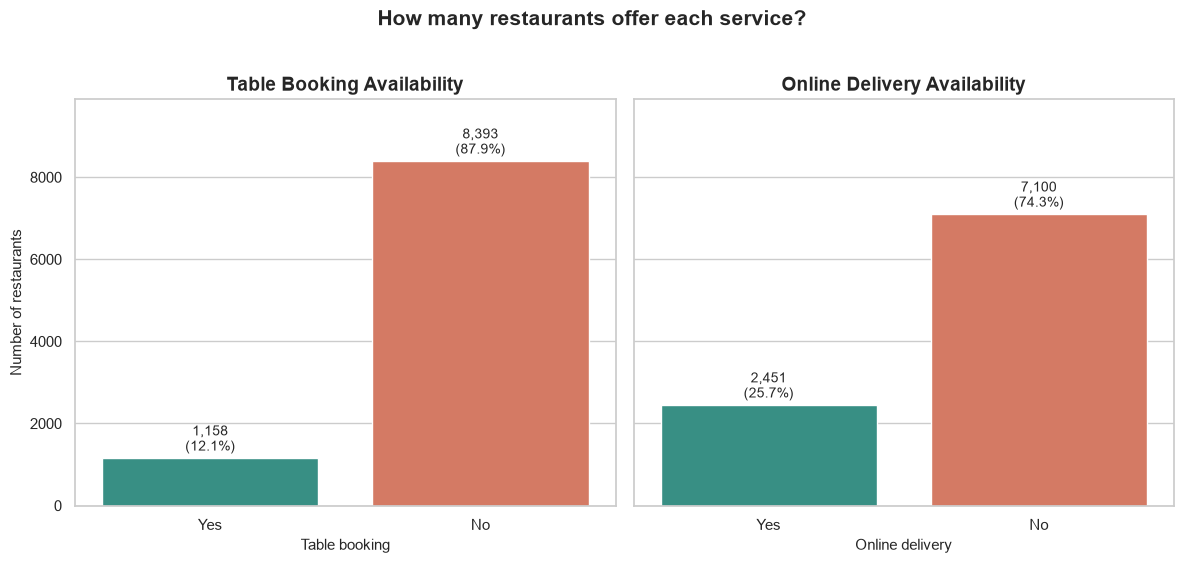

In [ ]:
service_palette = {"Yes": "#2a9d8f", "No": "#e76f51"}

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True)
panels = [
    (axes[0], booking_summary, "Table Booking Availability", "Table booking"),
    (axes[1], delivery_summary, "Online Delivery Availability", "Online delivery"),
]
y_max = max(booking_summary.loc[["Yes", "No"], "Restaurants"].max(),
            delivery_summary.loc[["Yes", "No"], "Restaurants"].max())

for ax, summary, title, xlabel in panels:
    plot_data = summary.loc[["Yes", "No"]]
    sns.barplot(x=plot_data.index, y=plot_data["Restaurants"], hue=plot_data.index,
                palette=service_palette, legend=False, ax=ax)
    for position, (_, row) in enumerate(plot_data.iterrows()):
        ax.text(position, row["Restaurants"] + y_max * 0.01,
                f"{row['Restaurants']:,.0f}\n({row['Percentage of all restaurants (%)']:.1f}%)",
                ha="center", va="bottom", fontsize=10)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Number of restaurants")
    ax.set_ylim(0, y_max * 1.18)

fig.suptitle("How many restaurants offer each service?", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

### 9.2 Average rating with and without table booking
Bars show the mean rating; the diamond marks the median, and the black line is one standard deviation either side of the mean.

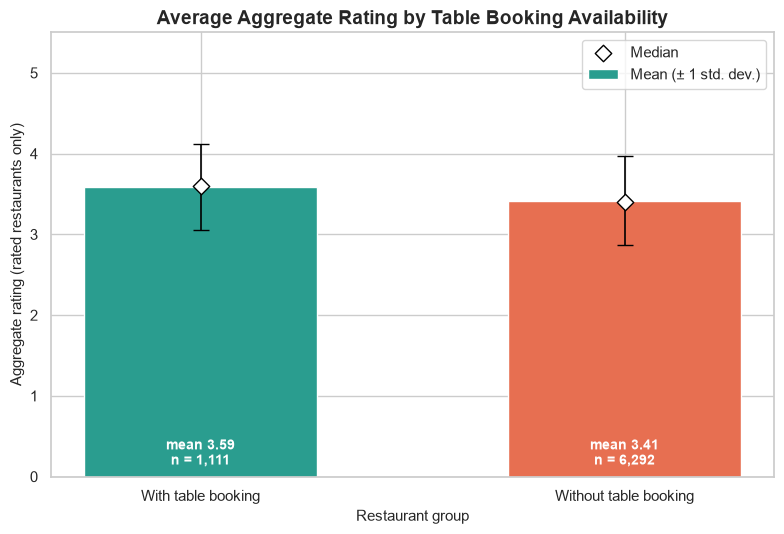

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5.5))
groups = rating_by_booking.index.tolist()
bar_colors = ["#2a9d8f", "#e76f51"]

ax.bar(groups, rating_by_booking["Mean Rating"], color=bar_colors, width=0.55,
       yerr=rating_by_booking["Std. Deviation"], capsize=6, error_kw={"ecolor": "black", "lw": 1.2},
       label="Mean (± 1 std. dev.)")
ax.scatter(groups, rating_by_booking["Median Rating"], marker="D", s=70, color="white",
           edgecolor="black", zorder=5, label="Median")

for position, (_, row) in enumerate(rating_by_booking.iterrows()):
    ax.text(position, 0.1, f"mean {row['Mean Rating']:.2f}\nn = {row['Rated Restaurants']:,.0f}",
            ha="center", va="bottom", fontsize=10, color="white", fontweight="bold")

ax.set_title("Average Aggregate Rating by Table Booking Availability")
ax.set_xlabel("Restaurant group")
ax.set_ylabel("Aggregate rating (rated restaurants only)")
ax.set_ylim(0, 5.5)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

### 9.3 Online delivery by price range (counts)

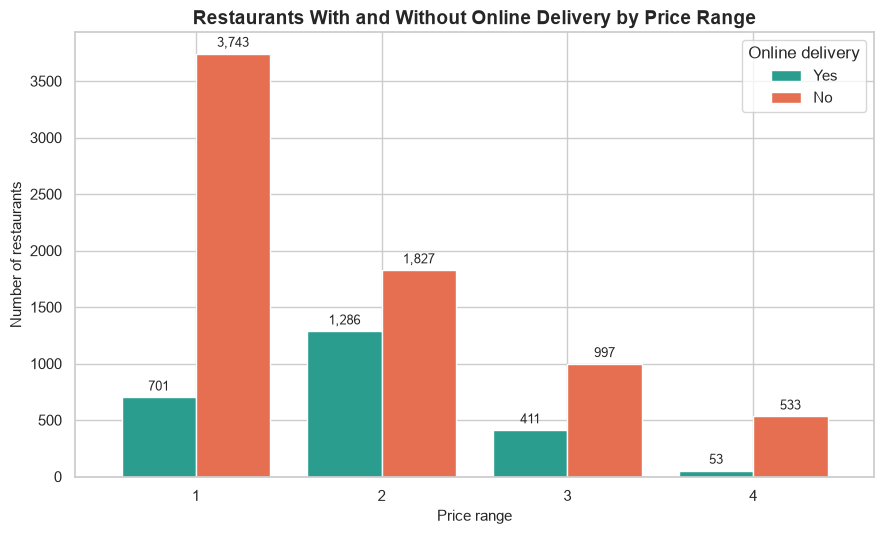

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5.5))
delivery_counts[["Yes", "No"]].plot(kind="bar", ax=ax, color=[service_palette["Yes"], service_palette["No"]],
                                    edgecolor="white", width=0.8)
for container in ax.containers:
    ax.bar_label(container, fmt="{:,.0f}", padding=3, fontsize=9)

ax.set_title("Restaurants With and Without Online Delivery by Price Range")
ax.set_xlabel("Price range")
ax.set_ylabel("Number of restaurants")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Online delivery")
plt.tight_layout()
plt.show()

### 9.4 Online delivery by price range (stacked percentage)
Each bar adds up to 100% so price ranges of very different sizes can be compared fairly.

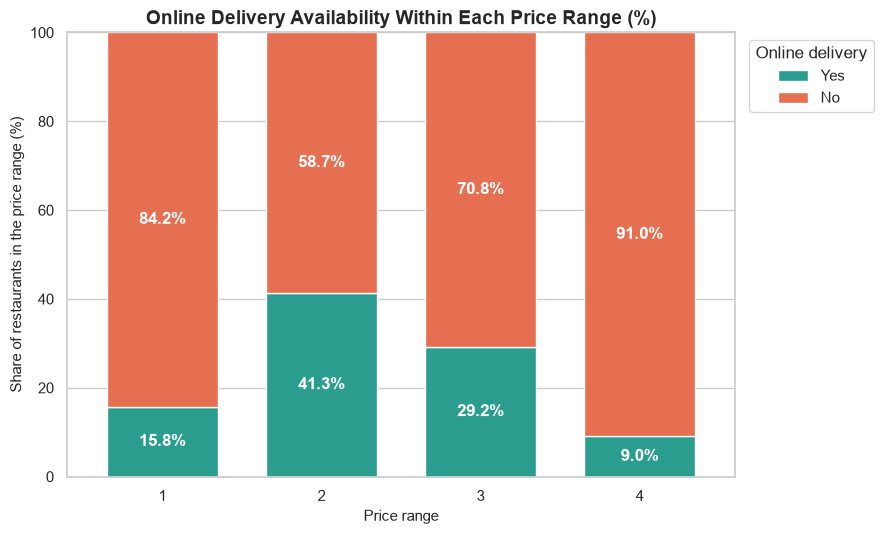

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5.5))
delivery_pct.plot(kind="bar", stacked=True, ax=ax,
                  color=[service_palette["Yes"], service_palette["No"]], edgecolor="white", width=0.7)

for container, column in zip(ax.containers, ["Yes", "No"]):
    labels = [f"{value:.1f}%" if value >= 3 else "" for value in delivery_pct[column]]
    ax.bar_label(container, labels=labels, label_type="center", color="white", fontweight="bold")

ax.set_title("Online Delivery Availability Within Each Price Range (%)")
ax.set_xlabel("Price range")
ax.set_ylabel("Share of restaurants in the price range (%)")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Online delivery", loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

## 10. Key Findings
The statements below are generated by code from the tables above, so they update automatically if the data changes.

In [ ]:
findings = []

# Table booking and online delivery prevalence
yes_book = booking_summary.loc["Yes"]
yes_deliv = delivery_summary.loc["Yes"]
findings.append(
    f"**Table booking:** {yes_book['Restaurants']:,.0f} of {len(df):,} restaurants "
    f"({yes_book['Percentage of all restaurants (%)']:.1f}%) offer table booking."
)
findings.append(
    f"**Online delivery:** {yes_deliv['Restaurants']:,.0f} of {len(df):,} restaurants "
    f"({yes_deliv['Percentage of all restaurants (%)']:.1f}%) offer online delivery."
)
more_common = "Online delivery" if yes_deliv["Restaurants"] > yes_book["Restaurants"] else "Table booking"
findings.append(f"**{more_common}** is the more widely offered of the two services.")

# Ratings with vs without table booking
if {"With table booking", "Without table booking"}.issubset(rating_by_booking.index):
    with_tb = rating_by_booking.loc["With table booking"]
    without_tb = rating_by_booking.loc["Without table booking"]
    gap = with_tb["Mean Rating"] - without_tb["Mean Rating"]
    direction = "higher" if gap > 0 else "lower" if gap < 0 else "the same"
    findings.append(
        f"**Ratings:** among rated restaurants, those with table booking average {with_tb['Mean Rating']:.2f} "
        f"(median {with_tb['Median Rating']:.2f}, std {with_tb['Std. Deviation']:.2f}) versus "
        f"{without_tb['Mean Rating']:.2f} (median {without_tb['Median Rating']:.2f}, "
        f"std {without_tb['Std. Deviation']:.2f}) without - a mean difference of {abs(gap):.2f} points ({direction} with booking)."
    )
    findings.append(
        "This is an association, not proof that offering table booking *causes* higher ratings; "
        "price level, location and restaurant type may also play a role."
    )

# Delivery across price ranges
if len(delivery_table):
    top_pr = delivery_table["With delivery (%)"].idxmax()
    low_pr = delivery_table["With delivery (%)"].idxmin()
    findings.append(
        f"**Delivery by price range:** delivery availability is highest in price range {top_pr} "
        f"({delivery_table.loc[top_pr, 'With delivery (%)']:.1f}% of its restaurants) and lowest in price range {low_pr} "
        f"({delivery_table.loc[low_pr, 'With delivery (%)']:.1f}%)."
    )
    pct_series = delivery_table["With delivery (%)"]
    if pct_series.is_monotonic_increasing:
        findings.append("Delivery availability rises steadily as the price range increases.")
    elif pct_series.is_monotonic_decreasing:
        findings.append("Delivery availability falls steadily as the price range increases.")
    else:
        findings.append("Delivery availability does not change in a single direction as the price range increases.")

# Data quality notes
findings.append(
    f"**Data quality:** {int((~df['Is Rated']).sum()):,} restaurants are unrated and were excluded from rating statistics; "
    f"{int(df['Table Booking'].isna().sum() + df['Online Delivery'].isna().sum()):,} Yes/No values were missing or unrecognised."
)

show_findings(findings)

- **Table booking:** 1,158 of 9,551 restaurants (12.1%) offer table booking.
- **Online delivery:** 2,451 of 9,551 restaurants (25.7%) offer online delivery.
- **Online delivery** is the more widely offered of the two services.
- **Ratings:** among rated restaurants, those with table booking average 3.59 (median 3.60, std 0.54) versus 3.41 (median 3.40, std 0.55) without - a mean difference of 0.17 points (higher with booking).
- This is an association, not proof that offering table booking *causes* higher ratings; price level, location and restaurant type may also play a role.
- **Delivery by price range:** delivery availability is highest in price range 2 (41.3% of its restaurants) and lowest in price range 4 (9.0%).
- Delivery availability does not change in a single direction as the price range increases.
- **Data quality:** 2,148 restaurants are unrated and were excluded from rating statistics; 0 Yes/No values were missing or unrecognised.

## 11. Conclusion
The code cell below writes the conclusion from the computed results.

In [ ]:
conclusion = [
    f"Out of {len(df):,} restaurants, {yes_book['Percentage of all restaurants (%)']:.1f}% accept table bookings and "
    f"{yes_deliv['Percentage of all restaurants (%)']:.1f}% offer online delivery.",
]
if {"With table booking", "Without table booking"}.issubset(rating_by_booking.index):
    conclusion.append(
        f"Restaurants with table booking have a mean rating of {with_tb['Mean Rating']:.2f} compared with "
        f"{without_tb['Mean Rating']:.2f} for those without, so table booking is "
        f"{'positively' if gap > 0 else 'negatively' if gap < 0 else 'not'} associated with ratings in this dataset."
    )
if len(delivery_table):
    conclusion.append(
        f"Online delivery availability varies by price range, from {delivery_table['With delivery (%)'].min():.1f}% "
        f"to {delivery_table['With delivery (%)'].max():.1f}%, so delivery availability differs noticeably between price ranges."
    )
conclusion.append(
    "Unrated restaurants (rating 0) were excluded from rating statistics and missing Yes/No values were kept as missing, "
    "so these results are not distorted by placeholder values."
)
show_findings(conclusion)

- Out of 9,551 restaurants, 12.1% accept table bookings and 25.7% offer online delivery.
- Restaurants with table booking have a mean rating of 3.59 compared with 3.41 for those without, so table booking is positively associated with ratings in this dataset.
- Online delivery availability varies by price range, from 9.0% to 41.3%, so delivery availability differs noticeably between price ranges.
- Unrated restaurants (rating 0) were excluded from rating statistics and missing Yes/No values were kept as missing, so these results are not distorted by placeholder values.